# TRUSTSR Lab 03.04 — Retry, Idempotency, and Reconciliation

**Phase:** Lab 03 — Reliability and evidence integrity  
**Status:** Synthetic local prototype | Version 0.1.0

## Objective
Lab 03.03 introduced a separate journal and reconciliation. This lab tests retry behavior when delivery fails or times out.

**Model**
- Each logical event has a stable `event_id`.
- Receiver stores at most one event per ID using a SQLite primary key.
- `transient_reject` simulates failure before storage.
- `timeout_after_store` simulates an ambiguous timeout after storage; retry must be deduplicated.
- Reconciliation compares intended IDs with receiver-stored IDs.
- Reusing an event ID with different payload is rejected.

**Evidence boundary:** deterministic synthetic simulation. No real network, remote service, production outage, or distributed system is tested.

## 1. Imports and simulated receiver

In [1]:
import os, json, sqlite3, tempfile, hashlib, sys
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("SQLite:", sqlite3.sqlite_version)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence classification: synthetic local simulation; no network calls")

fd, DB_PATH = tempfile.mkstemp(prefix="trustsr_lab03_04_", suffix=".sqlite")
os.close(fd)
receiver = sqlite3.connect(DB_PATH, isolation_level=None)
receiver.execute("PRAGMA synchronous=FULL")
receiver.execute("CREATE TABLE received_events (event_id TEXT PRIMARY KEY, event_type TEXT NOT NULL, payload_json TEXT NOT NULL, received_utc TEXT NOT NULL, payload_hash TEXT NOT NULL)")
print("Receiver initialized.")

Python: 3.12.3
SQLite: 3.45.1
Execution UTC: 2026-10-11T10:26:34.937310+00:00
Evidence classification: synthetic local simulation; no network calls
Receiver initialized.


## 2. Idempotent receiver and retry policy

In [2]:
def stable_hash(payload):
    encoded = json.dumps(payload, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode()
    return hashlib.sha256(encoded).hexdigest()

injected_behaviors = {}
def set_behaviors(event_id, behaviors):
    injected_behaviors[event_id] = list(behaviors)

def deliver(event, behavior="normal"):
    if behavior == "transient_reject":
        return {"status":"transient_failure_before_store","stored":False,"duplicate":False}
    event_id = event["event_id"]
    payload_json = json.dumps(event["payload"], sort_keys=True, separators=(",", ":"))
    payload_hash = stable_hash(event["payload"])
    existing = receiver.execute("SELECT payload_hash FROM received_events WHERE event_id=?", (event_id,)).fetchone()
    if existing:
        if existing[0] != payload_hash:
            return {"status":"idempotency_key_payload_conflict","stored":False,"duplicate":False}
        return {"status":"duplicate_ignored","stored":True,"duplicate":True}
    receiver.execute("INSERT INTO received_events VALUES (?,?,?,?,?)",
                     (event_id,event["event_type"],payload_json,datetime.now(timezone.utc).isoformat(),payload_hash))
    if behavior == "timeout_after_store":
        return {"status":"ambiguous_timeout_after_store","stored":True,"duplicate":False}
    return {"status":"accepted","stored":True,"duplicate":False}

def send_with_retries(event, max_attempts=3):
    attempts = []
    behaviors = injected_behaviors.get(event["event_id"], [])
    for attempt in range(1, max_attempts+1):
        behavior = behaviors.pop(0) if behaviors else "normal"
        result = deliver(event, behavior=behavior)
        attempts.append({"event_id":event["event_id"],"attempt":attempt,**result})
        if result["status"] in ("accepted","duplicate_ignored"):
            return {"event_id":event["event_id"],"delivered":True,"attempt_count":attempt,"final_status":result["status"],"attempts":attempts}
        if result["status"] == "idempotency_key_payload_conflict":
            return {"event_id":event["event_id"],"delivered":False,"attempt_count":attempt,"final_status":result["status"],"attempts":attempts}
    return {"event_id":event["event_id"],"delivered":False,"attempt_count":len(attempts),"final_status":"retry_exhausted","attempts":attempts}

print("Receiver and retry policy defined.")

Receiver and retry policy defined.


## 3. Run controlled scenarios

In [3]:
events = [
    {"event_id":"evt-001","event_type":"checkpoint_decision","payload":{"version":1,"outcome":"accepted"}},
    {"event_id":"evt-002","event_type":"operational_failure","payload":{"version":2,"reason":"synthetic_failure"}},
    {"event_id":"evt-003","event_type":"checkpoint_decision","payload":{"version":3,"outcome":"rejected"}},
    {"event_id":"evt-004","event_type":"recovery_decision","payload":{"version":4,"outcome":"quarantined"}},
]
set_behaviors("evt-001", ["normal"])
set_behaviors("evt-002", ["transient_reject","normal"])
set_behaviors("evt-003", ["timeout_after_store","normal"])
set_behaviors("evt-004", ["transient_reject","transient_reject","transient_reject"])

send_results, attempt_rows = [], []
for event in events:
    result = send_with_retries(event, max_attempts=3)
    send_results.append({k:v for k,v in result.items() if k!="attempts"})
    attempt_rows.extend(result["attempts"])

send_df = pd.DataFrame(send_results)
attempt_df = pd.DataFrame(attempt_rows)
display(send_df)
display(attempt_df)
by_id = send_df.set_index("event_id")
assert bool(by_id.loc["evt-001","delivered"])
assert bool(by_id.loc["evt-002","delivered"])
assert bool(by_id.loc["evt-003","delivered"])
assert not bool(by_id.loc["evt-004","delivered"])
assert "duplicate_ignored" in set(attempt_df["status"])
print("Scenario assertions passed.")

  event_id  delivered  attempt_count       final_status
0  evt-001       True              1           accepted
1  evt-002       True              2           accepted
2  evt-003       True              2  duplicate_ignored
3  evt-004      False              3    retry_exhausted

  event_id  attempt                          status  stored  duplicate
0  evt-001        1                        accepted    True      False
1  evt-002        1  transient_failure_before_store   False      False
2  evt-002        2                        accepted    True      False
3  evt-003        1   ambiguous_timeout_after_store    True      False
4  evt-003        2               duplicate_ignored    True       True
5  evt-004        1  transient_failure_before_store   False      False
6  evt-004        2  transient_failure_before_store   False      False
7  evt-004        3  transient_failure_before_store   False      False

Scenario assertions passed.


## 4. Reconciliation and duplicate protection

In [4]:
intended_ids = {e["event_id"] for e in events}
stored_rows = receiver.execute("SELECT event_id,event_type,payload_json,received_utc,payload_hash FROM received_events ORDER BY event_id").fetchall()
stored_ids = {r[0] for r in stored_rows}
reconciliation = []
for event in events:
    present = event["event_id"] in stored_ids
    result = by_id.loc[event["event_id"]]
    reconciliation.append({"event_id":event["event_id"],"intended":True,"stored_at_receiver":present,
                           "sender_reported_delivered":bool(result["delivered"]),
                           "reconciliation_status":"matched" if present else "missing_at_receiver"})
reconciliation_df = pd.DataFrame(reconciliation)
display(reconciliation_df)
receiver_count = int(receiver.execute("SELECT COUNT(*) FROM received_events").fetchone()[0])
duplicate_attempts = int((attempt_df["status"]=="duplicate_ignored").sum())
assert receiver_count == len(stored_ids) == 3
assert duplicate_attempts >= 1
assert bool(reconciliation_df.loc[reconciliation_df["event_id"]=="evt-003","stored_at_receiver"].iloc[0])
assert reconciliation_df.loc[reconciliation_df["event_id"]=="evt-004","reconciliation_status"].iloc[0] == "missing_at_receiver"
print({"intended_events":len(intended_ids),"receiver_unique_records":receiver_count,"duplicate_attempts_ignored":duplicate_attempts})

  event_id  intended  stored_at_receiver  sender_reported_delivered reconciliation_status
0  evt-001      True                True                       True               matched
1  evt-002      True                True                       True               matched
2  evt-003      True                True                       True               matched
3  evt-004      True               False                      False   missing_at_receiver

{'intended_events': 4, 'receiver_unique_records': 3, 'duplicate_attempts_ignored': 1}


## 5. Idempotency-key payload conflict

In [5]:
conflicting = {"event_id":"evt-001","event_type":"checkpoint_decision","payload":{"version":999,"outcome":"different_payload"}}
conflict_result = deliver(conflicting)
print("Payload conflict result:", conflict_result)
assert conflict_result["status"] == "idempotency_key_payload_conflict"
original_payload = receiver.execute("SELECT payload_json FROM received_events WHERE event_id='evt-001'").fetchone()[0]
assert json.loads(original_payload) == {"outcome":"accepted","version":1}
conflict_df = pd.DataFrame([
    {"test":"same_event_id_different_payload_rejected","passed":conflict_result["status"]=="idempotency_key_payload_conflict"},
    {"test":"original_payload_unchanged","passed":json.loads(original_payload)=={"outcome":"accepted","version":1}}
])
display(conflict_df)
assert conflict_df["passed"].all()

Payload conflict result: {'status': 'idempotency_key_payload_conflict', 'stored': False, 'duplicate': False}


                                       test  passed
0  same_event_id_different_payload_rejected    True
1                original_payload_unchanged    True

## 6. Plots and CSV exports

CSV exports created: delivery_summary, delivery_attempts, reconciliation, idempotency_conflict, receiver_records.


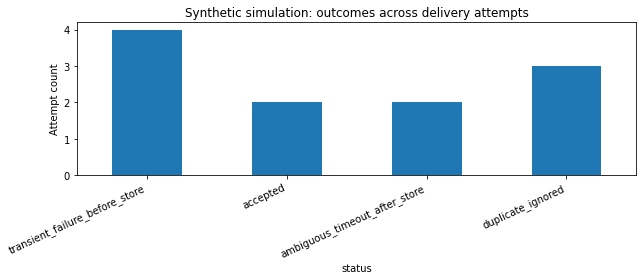

In [6]:
ax = send_df.set_index("event_id")["attempt_count"].plot(kind="bar", figsize=(8,4))
ax.set_title("Synthetic simulation: attempts required per event")
ax.set_ylabel("Delivery attempts")
plt.tight_layout()
plt.show()

ax = attempt_df["status"].value_counts().plot(kind="bar", figsize=(9,4))
ax.set_title("Synthetic simulation: outcomes across delivery attempts")
ax.set_ylabel("Attempt count")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

send_df.to_csv("trustsr_lab03_04_delivery_summary.csv", index=False)
attempt_df.to_csv("trustsr_lab03_04_delivery_attempts.csv", index=False)
reconciliation_df.to_csv("trustsr_lab03_04_reconciliation.csv", index=False)
conflict_df.to_csv("trustsr_lab03_04_idempotency_conflict.csv", index=False)
pd.DataFrame(stored_rows, columns=["event_id","event_type","payload_json","received_utc","payload_hash"]).to_csv("trustsr_lab03_04_receiver_records.csv", index=False)
print("CSV exports created: delivery_summary, delivery_attempts, reconciliation, idempotency_conflict, receiver_records.")

## 7. Final assertions and interpretation

**Expected:** All assertions pass.

### Defensible synthetic finding
Under the injected scenarios, the receiver stored each accepted `event_id` at most once. A simulated timeout after storage caused a retry, which was deduplicated. A transient pre-store failure was recovered by retry for one event, while another event exhausted its retry budget and remained absent. Reusing an idempotency key with a different payload was rejected.

### Limitations
- Local deterministic simulation, not a network benchmark.
- No latency, throughput, packet loss, consensus, or remote durability measured.
- Uniqueness is enforced only by this SQLite prototype.
- Retry safety depends on stable event IDs and receiver idempotency.
- A permanently unavailable receiver can still cause missing events.

### Next step
Use a larger parameterized simulation to measure retry counts, duplicate rate, missing-event rate, and sensitivity to retry limits. Keep outputs labelled synthetic until tested against an actual remote logging service.